If you're using IDE like VS Code, please install the **Jupyter** extension first.

The repeated failures (`Py4JNetworkError`) were caused by **insufficient memory allocated to Docker Desktop**, which made the Spark driver crash when processing large files.

**Please follow these steps exactly:**
1.  **Adjust Docker memory**:
    *   Locate the Docker whale icon in your system tray (bottom-right on Windows).
    *   Right-click it -> **Settings**.
    *   Left menu -> **Resources**.
    *   Find the **Memory** slider and **set it to at least 10 GB** (12 GB recommended if your machine has 16 GB or more).
    *   Click **Apply & Restart**.
     ### Or
    * WIN + R -> %USERPROFILE%
    * create a file named .wslconfig
    * add the following line to the file:

    [wsl2]
    memory=12GB

2.  **Restart the notebook kernel**:
    *   After Docker has restarted, return to this page. 
    *   Follow the hint in Phase 1&2 to restart the kernel.
3.  **Run the cells below in order**.
4.  **Please don't run the second cell only if you have to**.

**if you are fluently aborted from the JVM, please follow the step above**

## [README]
This notebook requires **docker desktop**.

once downloaded, type(copy and paste) the following command in the terminal:

docker-compose up -d

Once the command is executed, type the following command in the terminal to get the token:

### Alternative
Run (copy and paste) the following command in a terminal to generate a token, then paste it into the link below.

http://127.0.0.1:8888/lab?token=XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX


docker exec jupyter_analytics jupyter server list

### Recommended
Run the above command, copy the output link NOT INCLUDED **:: //home/jovyan**. 

Go to your notebook and click **Select Kernel** in the top-right corner.

Go to **Select Another Kernel...** > **Existing Jupyter Server...** and paste **output link** and replace the number and letter combination after the http:// with **localhost** in the input box.

e.g. http://5ab7977b7ef1:8888/?token=28737xxxxxxxxxxxxxxxxxxxxxxxxxxxxcf55d5 

➡️ http://localhost:8888/?token=28737xxxxxxxxxxxxxxxxxxxxxxxxxxxxcf55d5

Hit Enter, then Enter again... and you're in!

🚨 AND DO **NOT** FORGET to run the **First cell** before you do anything else!




Please run the first cell to initialize the spark,

If you make a mistake in editing the following cells, no worries — just switch the second cell from Markdown to Python,

run it, and switch it back.

The following cells are just AI generated and serve as a runnable skeleton.[Don't foget to remove this sentence!]

The actual implementation details and business logic need to be carefully filled in by each student.





In [1]:
import time
t_start_p3_p4 = time.time()

# PHASE 3 Data Storage and Cleansing

In [2]:
# Must run after restarting
# Spark Session Init (8GB RAM)
# ==========================================
import os
from pyspark.sql import SparkSession

# 1. Set HDFS Identity to 'root' for full permissions
os.environ['HADOOP_USER_NAME'] = 'root'
os.chdir('/home/jovyan/work')

# 2. Stop any existing session
if SparkSession.getActiveSession():
    SparkSession.getActiveSession().stop()

# 3. Initialize Spark with 8GB Memory
spark = SparkSession.builder \
    .appName("Phase3_Process_Storage") \
    .master("local[*]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.memory.offHeap.enabled", "true") \
    .config("spark.memory.offHeap.size", "2g") \
    .config("spark.hadoop.fs.defaultFS", "hdfs://namenode:9000") \
    .config("spark.sql.caseSensitive", "true") \
    .getOrCreate()

print(f"✅ Spark Ready! Driver Memory: 8g")

✅ Spark Ready! Driver Memory: 8g


#Do NOT run this cell only if you crush the data

#Press Enter and change markdown to python when you decide to run this cell

print("🧹 Wiping HDFS /ecommerce...")
try:
    fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
    fs.delete(spark._jvm.org.apache.hadoop.fs.Path("/ecommerce"), True)
    print("✅ HDFS Cleaned.")
except Exception as e:
    print(f"❌ Cleanup failed: {e}")

In [4]:
# Sync Local Data to HDFS (with MORE Partitions)
# ============================================
# Ensure data have extracted to data_lake folder
if os.path.exists("configs/local"): # If local files exist, skip the sync
    print("[SKIP LOCAL] skip the sync")

else:
    import os

    with open("configs/datasets.txt", 'r') as f:
        lines = [line.strip() for line in f if line.strip()]

    datasets = []
    for types in ["meta", "review"]:
        for line in lines:
            parts = line.split(',')
            # dataset_name = parts[0].strip()
            table_name = parts[1].strip()
            local_path = f"data_lake/{types}_{table_name}.parquet"
            hdfs_path = f"/ecommerce/data_lake/{types}/{types}_{table_name}"
            datasets.append((local_path, hdfs_path))

    for local_p, hdfs_p in datasets:
        if os.path.exists(local_p):
            print(f" Syncing {local_p}...")
            df = spark.read.parquet(f"file://{os.path.abspath(local_p)}").repartition(32)
            df.write.mode("overwrite").parquet(hdfs_p)
            print(f" Done: {hdfs_p}")
        else:
            print(f" X Local file not found: {local_p}")

    print("\n Data synchronization complete!")

 Syncing data_lake/meta_elec.parquet...
 Done: /ecommerce/data_lake/meta/meta_elec
 Syncing data_lake/meta_cellp.parquet...
 Done: /ecommerce/data_lake/meta/meta_cellp
 Syncing data_lake/review_elec.parquet...
 Done: /ecommerce/data_lake/review/review_elec
 Syncing data_lake/review_cellp.parquet...
 Done: /ecommerce/data_lake/review/review_cellp

 Data synchronization complete!


In [5]:
meta_path = "/ecommerce/data_lake/meta/*"
review_path = "/ecommerce/data_lake/review/*"

def preview_parquet(label, path):
    print(f"\n=== {label} ===")
    print(f"Path: {path}")
    df = spark.read.parquet(path)
    print(f"Columns ({len(df.columns)}): {df.columns}")
    df.printSchema()
    df.limit(5).show(5, truncate=60)
    try:
        print(f"Partitions: {df.rdd.getNumPartitions()}")
    except Exception:
        pass

preview_parquet("RAW META (HDFS)", meta_path)
preview_parquet("RAW REVIEW (HDFS)", review_path)

print("\n✅ Data preview finished (no full count performed).")


=== RAW META (HDFS) ===
Path: /ecommerce/data_lake/meta/*
Columns (8): ['parent_asin', 'title', 'price', 'store', 'main_category', 'average_rating', 'rating_number', 'details']
root
 |-- parent_asin: string (nullable = true)
 |-- title: string (nullable = true)
 |-- price: float (nullable = true)
 |-- store: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- average_rating: float (nullable = true)
 |-- rating_number: long (nullable = true)
 |-- details: string (nullable = true)

+-----------+------------------------------------------------------------+------+--------+--------------------+--------------+-------------+------------------------------------------------------------+
|parent_asin|                                                       title| price|   store|       main_category|average_rating|rating_number|                                                     details|
+-----------+------------------------------------------------------------+------+------

## Member 2
### Data Quality Engineer

In [ ]:
# ==========================================
# Member 2: Data Quality Engineer
# Data Cleaning + Price Outlier Detection (Boxplot IQR)
# ==========================================
# Note: We do NOT deduplicate by `asin`.
# Rationale: `parent_asin` is treated as the primary product-family identifier, while `asin` can represent different variants/parameters under the same parent.
# Keeping multiple rows per `parent_asin` preserves variant-level metadata for downstream analysis.

from pyspark.sql import functions as F
from pyspark.sql.functions import col

# ========== Read raw data ==========
from functools import reduce

# Spark initialization
# Run the first Cell

# Get local data to HDFS
# Run the above cells

meta_elec = spark.read.parquet("/ecommerce/data_lake/meta/meta_elec")
meta_cellp = spark.read.parquet("/ecommerce/data_lake/meta/meta_cellp")
meta_raw = meta_elec.union(meta_cellp)

review_elec = spark.read.parquet("/ecommerce/data_lake/review/review_elec")
review_cellp = spark.read.parquet("/ecommerce/data_lake/review/review_cellp")
review_raw = review_elec.union(review_cellp)

print("✅ Raw data loaded successfully")
print(f"   meta_raw record count: {meta_raw.count():,}")
print(f"   review_raw record count: {review_raw.count():,}")

# ========== 1. META data cleaning ==========
meta_clean = meta_raw

# 1.1 Filter out null parent_asin
if "parent_asin" in meta_clean.columns:
    before = meta_clean.count()
    meta_clean = meta_clean.filter(F.col("parent_asin").isNotNull())
    after = meta_clean.count()
    print(f"\n📌 META: Filter null parent_asin -> Removed {before - after:,} rows")

# 1.2 Price cleaning + filter null/zero price + boxplot IQR outlier detection
if "price" in meta_clean.columns:
    # Step 1: Extract numbers, convert to double
    meta_clean = meta_clean.withColumn("price", F.col("price").cast("double"))
    
    # Step 2: Filter out null or <=0 price records
    before = meta_clean.count()
    meta_clean = meta_clean.filter(F.col("price").isNotNull() & (F.col("price") > 0))
    after = meta_clean.count()
    print(f"\n📌 META: Filter null/invalid price -> Removed {before - after:,} rows")
    
    # Step 3: Boxplot IQR outlier detection and filtering
    if meta_clean.count() > 0:
        quantiles = meta_clean.approxQuantile("price", [0.25, 0.75], 0.05)
        Q1 = quantiles[0]
        Q3 = quantiles[1]
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        before = meta_clean.count()
        meta_clean = meta_clean.filter(
            (F.col("price") >= lower_bound) & (F.col("price") <= upper_bound)
        )
        after = meta_clean.count()
        
        print(f"\n📊 META: Price outlier detection (Boxplot IQR)")
        print(f"   Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
        print(f"   Normal price range: {lower_bound:.2f} ~ {upper_bound:.2f}")
        print(f"   Removed {before - after:,} outlier price records")
    else:
        print("\n⚠️ Warning: No valid data after filtering null price, skipping outlier detection")

# 1.3 Deduplication
if "parent_asin" in meta_clean.columns and "asin" in meta_clean.columns:
    before = meta_clean.count()
    meta_clean = meta_clean.dropDuplicates(["parent_asin", "asin"])
    after = meta_clean.count()
    print(f"\n📌 META: Deduplicate(parent_asin, asin) -> Removed {before - after:,} rows")
elif "parent_asin" in meta_clean.columns:
    before = meta_clean.count()
    meta_clean = meta_clean.dropDuplicates(["parent_asin"])
    after = meta_clean.count()
    print(f"\n📌 META: Deduplicate(parent_asin) -> Removed {before - after:,} rows")
else:
    before = meta_clean.count()
    meta_clean = meta_clean.dropDuplicates()
    after = meta_clean.count()
    print(f"\n📌 META: Deduplicate(all columns) -> Removed {before - after:,} rows")

print(f"\n✅ META cleaning completed! Final record count: {meta_clean.count():,}")

# ========== 2. REVIEW data cleaning ==========
review_clean = review_raw

# Helper function: timestamp conversion (milliseconds -> seconds)
def to_unix_seconds(col):
    ts = col.cast("long")
    return F.when(ts > F.lit(20000000000), (ts / 1000).cast("long")).otherwise(ts)

# 2.1 Standardize column names
if "overall" not in review_clean.columns and "rating" in review_clean.columns:
    review_clean = review_clean.withColumn("overall", F.col("rating").cast("double"))
if "reviewText" not in review_clean.columns and "text" in review_clean.columns:
    review_clean = review_clean.withColumn("reviewText", F.col("text").cast("string"))
if "reviewerID" not in review_clean.columns and "user_id" in review_clean.columns:
    review_clean = review_clean.withColumn("reviewerID", F.col("user_id").cast("string"))

# 2.2 Timestamp processing
if "unixReviewTime" not in review_clean.columns:
    if "timestamp" in review_clean.columns:
        review_clean = review_clean.withColumn("unixReviewTime", to_unix_seconds(F.col("timestamp")))
    elif "time" in review_clean.columns:
        review_clean = review_clean.withColumn("unixReviewTime", to_unix_seconds(F.col("time")))

# 2.3 Filter rating range (1-5)
if "overall" in review_clean.columns:
    before = review_clean.count()
    review_clean = review_clean.filter((F.col("overall") >= 1) & (F.col("overall") <= 5))
    after = review_clean.count()
    print(f"\n📌 REVIEW: Filter rating range 1-5 -> Removed {before - after:,} rows")

# 2.4 Clean review text
if "reviewText" in review_clean.columns:
    review_clean = review_clean.withColumn("reviewText", F.trim(F.col("reviewText")))

# 2.5 Filter null asin
if "asin" in review_clean.columns:
    before = review_clean.count()
    review_clean = review_clean.filter(F.col("asin").isNotNull())
    after = review_clean.count()
    print(f"\n📌 REVIEW: Filter null asin -> Removed {before - after:,} rows")

# 2.6 Filter null timestamp
if "unixReviewTime" in review_clean.columns:
    before = review_clean.count()
    review_clean = review_clean.filter(F.col("unixReviewTime").isNotNull())
    after = review_clean.count()
    print(f"\n📌 REVIEW: Filter null unixReviewTime -> Removed {before - after:,} rows")
    
    # Add date and year_month fields
    review_clean = review_clean.withColumn("review_date", F.from_unixtime(F.col("unixReviewTime")).cast("date"))
    review_clean = review_clean.withColumn("year_month", F.date_format(F.col("review_date"), "yyyy-MM"))

# 2.7 Filter empty review text
if "reviewText" in review_clean.columns:
    before = review_clean.count()
    review_clean = review_clean.filter(F.col("reviewText").isNotNull() & (F.length(F.col("reviewText")) > 0))
    after = review_clean.count()
    print(f"\n📌 REVIEW: Filter empty review text -> Removed {before - after:,} rows")

# 2.8 Deduplication
dedup_keys = [c for c in ["reviewerID", "asin", "unixReviewTime"] if c in review_clean.columns]
if dedup_keys:
    before = review_clean.count()
    review_clean = review_clean.dropDuplicates(dedup_keys)
    after = review_clean.count()
    print(f"\n📌 REVIEW: Deduplicate({dedup_keys}) -> Removed {before - after:,} rows")
else:
    before = review_clean.count()
    review_clean = review_clean.dropDuplicates()
    after = review_clean.count()
    print(f"\n📌 REVIEW: Deduplicate(all columns) -> Removed {before - after:,} rows")

print(f"\n✅ REVIEW cleaning completed! Final record count: {review_clean.count():,}")

# ========== 3. Save cleaned data ==========
meta_out = "/ecommerce/data_lake/clean/meta"
review_out = "/ecommerce/data_lake/clean/review"

meta_partitions = max(32, spark.sparkContext.defaultParallelism)
review_partitions = max(128, spark.sparkContext.defaultParallelism * 2)

print(f"\n💾 Saving cleaned data...")
print(f"   meta output path: {meta_out}")
print(f"   review output path: {review_out}")

meta_clean.repartition(meta_partitions).write.mode("overwrite").parquet(meta_out)

if "year_month" in review_clean.columns:
    review_clean.repartition(review_partitions, "year_month").write.mode("overwrite").partitionBy("year_month").parquet(review_out)
else:
    review_clean.repartition(review_partitions).write.mode("overwrite").parquet(review_out)

print(f"\n✅ All tasks completed!")
print(f"   META saved to: {meta_out}")
print(f"   REVIEW saved to: {review_out}")

# ========== 4. Brief audit report ==========
print("\n" + "="*60)
print("📊 Cleaning Summary")
print("="*60)
print(f"Original META record count:   {meta_raw.count():,}")
print(f"Cleaned META record count: {meta_clean.count():,}")
print(f"")
print(f"Original REVIEW record count:   {review_raw.count():,}")
print(f"Cleaned REVIEW record count: {review_clean.count():,}")
print("="*60)
# ========== 5. Validate cleaning results ==========
print("\n" + "="*60)
print("📈 Data Quality Validation Report")
print("="*60)

# Re-read cleaned data (from HDFS)
print("\n1️⃣ Reading cleaned data...")
df_meta_clean_verify = spark.read.parquet("/ecommerce/data_lake/clean/meta")
df_review_clean_verify = spark.read.parquet("/ecommerce/data_lake/clean/review")

meta_count = df_meta_clean_verify.count()
review_count = df_review_clean_verify.count()
print(f"   META cleaned record count: {meta_count:,}")
print(f"   REVIEW cleaned record count: {review_count:,}")

# Price statistics (if price column exists)
if "price" in df_meta_clean_verify.columns:
    print("\n2️⃣ Price field statistics:")
    price_stats = df_meta_clean_verify.select(
        F.min("price").alias("min"),
        F.max("price").alias("max"),
        F.avg("price").alias("avg"),
        F.expr("percentile_approx(price, 0.5)").alias("median"),
        F.expr("percentile_approx(price, 0.25)").alias("q1"),
        F.expr("percentile_approx(price, 0.75)").alias("q3")
    ).collect()[0]
    
    print(f"   Min price: ${price_stats['min']:.2f}")
    print(f"   Max price: ${price_stats['max']:.2f}")
    print(f"   Avg price: ${price_stats['avg']:.2f}")
    print(f"   Median: ${price_stats['median']:.2f}")
    print(f"   Q1: ${price_stats['q1']:.2f}, Q3: ${price_stats['q3']:.2f}")
    print(f"   IQR: ${price_stats['q3'] - price_stats['q1']:.2f}")

# Rating distribution (if rating field exists)
if "average_rating" in df_meta_clean_verify.columns:
    print("\n3️⃣ Rating distribution:")
    rating_dist = df_meta_clean_verify.groupBy("average_rating").count().orderBy("average_rating")
    rating_dist.show(10, truncate=False)

print("\n✅ Validation completed!")

✅ Raw data loaded successfully
   meta_raw record count: 146,229
   review_raw record count: 6,945,481

📌 META: Filter null parent_asin -> Removed 0 rows

📌 META: Filter null/invalid price -> Removed 102,422 rows

📊 META: Price outlier detection (Boxplot IQR)
   Q1 = 39.99, Q3 = 398.00, IQR = 358.01
   Normal price range: -497.02 ~ 935.01
   Removed 4,811 outlier price records

📌 META: Deduplicate(parent_asin) -> Removed 0 rows

✅ META cleaning completed! Final record count: 38,996

📌 REVIEW: Filter rating range 1-5 -> Removed 0 rows

📌 REVIEW: Filter null asin -> Removed 0 rows

📌 REVIEW: Filter null unixReviewTime -> Removed 0 rows

📌 REVIEW: Filter empty review text -> Removed 4,302 rows

📌 REVIEW: Deduplicate(['reviewerID', 'asin', 'unixReviewTime']) -> Removed 74,874 rows

✅ REVIEW cleaning completed! Final record count: 6,866,305

💾 Saving cleaned data...
   meta output path: /ecommerce/data_lake/clean/meta
   review output path: /ecommerce/data_lake/clean/review

✅ All tasks com


📊 Collecting price data for visualization
   Raw price data before cleaning: 43,807 records
   Valid numeric prices before cleaning: 43,781 records
   Raw price data after cleaning: 38,996 records
   Valid numeric prices after cleaning: 38,996 records


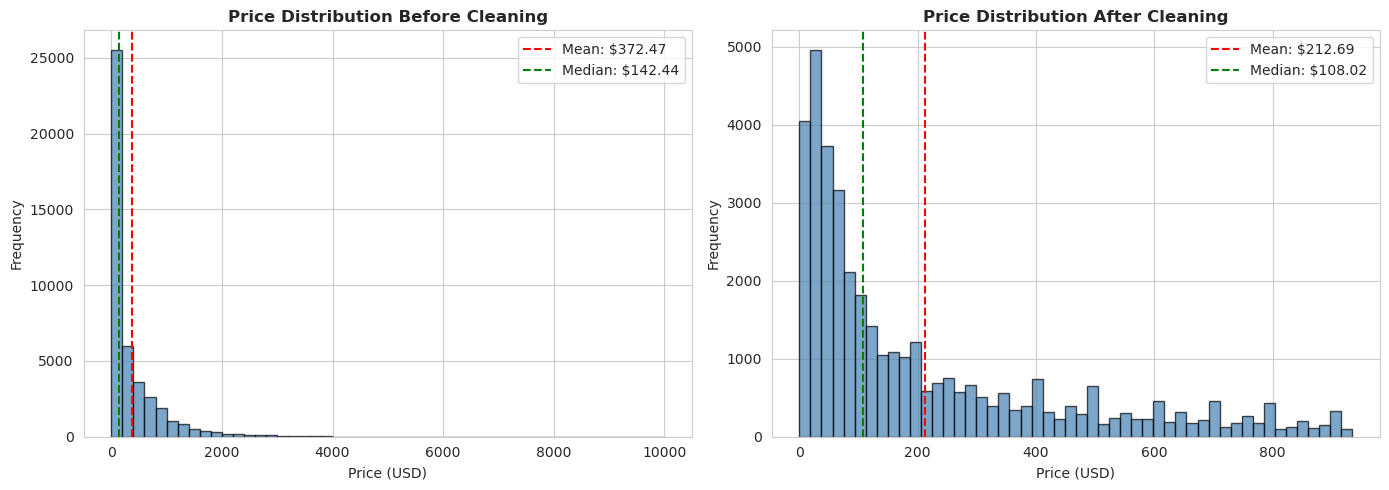

✅ Histogram saved as pngs/M2/price_cleaning_comparison.png


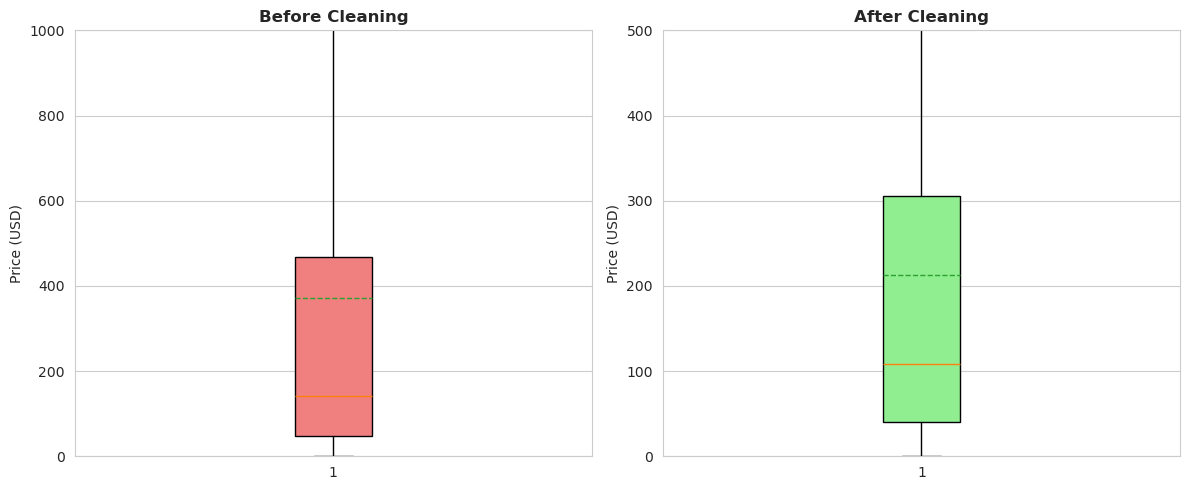

✅ Boxplot saved as pngs/M2/price_boxplot_comparison.png

📊 Price Statistics Summary

Before Cleaning:
   Count: 43,781
   Min: $0.02
   Max: $9999.00
   Mean: $372.47
   Median: $142.44
   Std Dev: $601.73

After Cleaning:
   Count: 38,996
   Min: $0.02
   Max: $935.00
   Mean: $212.69
   Median: $108.02
   Std Dev: $233.35

✅ Visualization completed successfully!


In [7]:
print("\n" + "="*60)
print("📊 Collecting price data for visualization")
print("="*60)

# ========== 1. Collect and clean price data ==========
def safe_convert_to_float(data_list):
    """Safely convert list to float values, filtering invalid entries"""
    result = []
    for x in data_list:
        try:
            if x is not None and str(x).strip():
                # Convert to string and clean
                cleaned = str(x).strip().replace('$', '').replace(',', '')
                val = float(cleaned)
                # Keep only positive prices within reasonable range (< 10000)
                if 0 < val < 10000:
                    result.append(val)
        except (ValueError, TypeError):
            continue
    return result

# Collect price data before cleaning (from raw data)
price_before_raw = meta_raw.select("price").filter(
    F.col("price").isNotNull() & (F.col("price") > 0)
).rdd.flatMap(lambda x: x).collect()

# Collect price data after cleaning (from cleaned data)
price_after_raw = df_meta_clean_verify.select("price").rdd.flatMap(lambda x: x).collect()

# Convert to pure numeric lists
price_before = safe_convert_to_float(price_before_raw)
price_after = safe_convert_to_float(price_after_raw)

print(f"   Raw price data before cleaning: {len(price_before_raw):,} records")
print(f"   Valid numeric prices before cleaning: {len(price_before):,} records")
print(f"   Raw price data after cleaning: {len(price_after_raw):,} records")
print(f"   Valid numeric prices after cleaning: {len(price_after):,} records")

# Check if we have valid data
if len(price_before) == 0 or len(price_after) == 0:
    print("⚠️ Warning: No valid numeric price data for plotting")
else:
    # ========== 2. Histogram (Price Distribution) ==========
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    
    # Set style
    sns.set_style("whitegrid")
    
    # Price distribution comparison before and after cleaning
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Before cleaning
    axes[0].hist(price_before, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0].set_title('Price Distribution Before Cleaning', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Price (USD)')
    axes[0].set_ylabel('Frequency')
    # Add mean and median lines
    axes[0].axvline(x=np.mean(price_before), color='red', linestyle='--', linewidth=1.5, label=f'Mean: ${np.mean(price_before):.2f}')
    axes[0].axvline(x=np.median(price_before), color='green', linestyle='--', linewidth=1.5, label=f'Median: ${np.median(price_before):.2f}')
    axes[0].legend()
    
    # After cleaning
    axes[1].hist(price_after, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    axes[1].set_title('Price Distribution After Cleaning', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Price (USD)')
    axes[1].set_ylabel('Frequency')
    axes[1].axvline(x=np.mean(price_after), color='red', linestyle='--', linewidth=1.5, label=f'Mean: ${np.mean(price_after):.2f}')
    axes[1].axvline(x=np.median(price_after), color='green', linestyle='--', linewidth=1.5, label=f'Median: ${np.median(price_after):.2f}')
    axes[1].legend()
    
    plt.tight_layout()
    
    output_path = 'pngs/M2/price_cleaning_comparison.png'
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Histogram saved as {output_path}")
    
    # ========== 3. Boxplot (Outlier Comparison) ==========
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Before cleaning
    bp1 = axes[0].boxplot(price_before, vert=True, patch_artist=True, 
                          showmeans=True, meanline=True)
    axes[0].set_title('Before Cleaning', fontweight='bold', fontsize=12)
    axes[0].set_ylabel('Price (USD)')
    axes[0].set_ylim(0, min(max(price_before) * 1.1, 1000))  # Limit Y-axis range
    
    # After cleaning
    bp2 = axes[1].boxplot(price_after, vert=True, patch_artist=True,
                          showmeans=True, meanline=True)
    axes[1].set_title('After Cleaning', fontweight='bold', fontsize=12)
    axes[1].set_ylabel('Price (USD)')
    axes[1].set_ylim(0, min(max(price_after) * 1.1, 500))
    
    # Add colors to boxes
    for box in bp1['boxes']:
        box.set_facecolor('lightcoral')
    for box in bp2['boxes']:
        box.set_facecolor('lightgreen')
    
    plt.tight_layout()

    output_path = 'pngs/M2/price_boxplot_comparison.png'
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Boxplot saved as {output_path}")
    
    # ========== 4. Print statistical summary ==========
    print("\n" + "="*60)
    print("📊 Price Statistics Summary")
    print("="*60)
    
    print("\nBefore Cleaning:")
    print(f"   Count: {len(price_before):,}")
    print(f"   Min: ${min(price_before):.2f}")
    print(f"   Max: ${max(price_before):.2f}")
    print(f"   Mean: ${np.mean(price_before):.2f}")
    print(f"   Median: ${np.median(price_before):.2f}")
    print(f"   Std Dev: ${np.std(price_before):.2f}")
    
    print("\nAfter Cleaning:")
    print(f"   Count: {len(price_after):,}")
    print(f"   Min: ${min(price_after):.2f}")
    print(f"   Max: ${max(price_after):.2f}")
    print(f"   Mean: ${np.mean(price_after):.2f}")
    print(f"   Median: ${np.median(price_after):.2f}")
    print(f"   Std Dev: ${np.std(price_after):.2f}")
    
    print("\n" + "="*60)
    print("✅ Visualization completed successfully!")

In [8]:
# Cleaned Data Summary (HDFS)
# ==========================================
meta_written = spark.read.parquet(meta_out)
review_written = spark.read.parquet(review_out)

m_count = meta_written.count()
m_columns = meta_written.columns
r_count = review_written.count()
r_columns = review_written.columns
print(meta_written.show(5))
print(review_written.show(5))

print("📊 Cleaned HDFS Data Summary:")
print(f"   - Meta Clean Records  : {m_count:,}")
print(f"   - Meta Clean Columns  : {m_columns}\n")
print(f"   - Review Clean Records: {r_count:,}")
print(f"   - Review Clean Columns: {r_columns}\n")

if "year_month" in review_written.columns:
    month_count = review_written.select("year_month").distinct().count()
    bounds = review_written.selectExpr("min(year_month) as min_ym", "max(year_month) as max_ym").collect()[0]
    print(f"   - Months             : {month_count:,} ({bounds['min_ym']} ~ {bounds['max_ym']})")

+-----------+--------------------+------------------+----------+--------------------+--------------+-------------+--------------------+
|parent_asin|               title|             price|     store|       main_category|average_rating|rating_number|             details|
+-----------+--------------------+------------------+----------+--------------------+--------------+-------------+--------------------+
| B07GSFZVQT|Bose Bose S1 Pro ...|              35.0|      Bose|Cell Phones & Acc...|           4.5|         1383|{"Product Dimensi...|
| B08SB72PC4|VIVO Height Adjus...|19.989999771118164|      VIVO|     All Electronics|           4.3|          917|{"Brand Name": "V...|
| B001RQ6CAI|Blackberry C-S2 7...|  16.6200008392334|BlackBerry|     All Electronics|           4.2|           48|{"Package Dimensi...|
| B008NA1K0S|ASUS P8H61-M LE/C...|106.98999786376953|      ASUS|           Computers|           3.9|          123|{"Processor": "co...|
| B07RV4CDF2|JBL E55BTBLK / JB...|             1

In [9]:
# Example Data Testing
# ==========================================

from pyspark.sql import functions as F

Path = spark._jvm.org.apache.hadoop.fs.Path
fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())

assert fs.exists(Path(meta_out)), f"Missing HDFS path: {meta_out}"
assert fs.exists(Path(review_out)), f"Missing HDFS path: {review_out}"

meta_written = spark.read.parquet(meta_out)
review_written = spark.read.parquet(review_out)

assert len(meta_written.take(1)) > 0, "meta_out is empty"
assert len(review_written.take(1)) > 0, "review_out is empty"

if "parent_asin" in meta_written.columns:
    assert meta_written.filter(F.col("parent_asin").isNull()).limit(1).count() == 0, "meta_clean has null parent_asin"
if "price" in meta_written.columns:
    pass
    
    # assert meta_written.filter(F.col("price").isNull()).limit(1).count() == 0, "meta_clean has null price"

if "overall" in review_written.columns:
    assert review_written.filter((F.col("overall") < 1) | (F.col("overall") > 5) | F.col("overall").isNull()).limit(1).count() == 0, "review_clean has invalid overall"
if "reviewText" in review_written.columns:
    assert review_written.filter(F.col("reviewText").isNotNull() & (F.col("reviewText") != F.trim(F.col("reviewText")))).limit(1).count() == 0, "review_clean has untrimmed reviewText"

print("✅ Full-pipeline cleaning/saving tests passed")

✅ Full-pipeline cleaning/saving tests passed


In [10]:
meta_out = "/ecommerce/data_lake/clean/meta"
review_out = "/ecommerce/data_lake/clean/review"

In [11]:
# Category-aware Dual-Feature Clustering (Word2Vec + Custom Stopwords)
# --------------- Member 3 -----------------
# ==========================================
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml.clustering import KMeans
from pyspark.ml.feature import CountVectorizer, Tokenizer, StopWordsRemover, Word2Vec, VectorAssembler, Normalizer
# Import PCA for dimensionality reduction
from pyspark.ml.feature import PCA
# Add MinMaxScaler for normalization
from pyspark.ml.feature import MinMaxScaler, VectorAssembler
from datetime import date, datetime

TARGET_CATEGORIES = {
    "All Electronics": "El",
    "Camera & Photo": "Ca",
    "Cell Phones & Accessories": "Ce",
    "Computers": "Co",
    "Home Audio & Theater": "Ha",
}

CLUSTER_K = {
    "All Electronics": 5,
    "Camera & Photo": 4,
    "Cell Phones & Accessories": 5,
    "Computers": 6,
    "Home Audio & Theater": 4,
}

CUSTOM_BRANDS = [
     # Smartphones / Tablets
    "apple", "samsung", "galaxy", "google", "sony", "oneplus", "xiaomi", "oppo", "huawei",
    "motorola", "nokia", "realme", "vivo", "zte", "blackberry", "honor",
    # Laptops / PCs
    "dell", "hp", "lenovo", "asus", "acer", "microsoft", "razer", "msi",
    "toshiba", "gigabyte", "|lg", "alienware", "system76",
    # Audio
    "bose", "jbl", "sennheiser", "jabra", "anker", "soundcore",
    "beats", "shure", "audio-technica", "skullcandy",
    "plantronics", "beyerdynamic", "marshall",
    # Gaming Peripherals
    "logitech", "corsair", "steelseries", "hyperx", "roccat",
    "zowie", "glorious", "ducky",
    # Cameras
    "canon", "nikon", "fujifilm", "gopro",
    "panasonic", "olympus", "leica", "dji", "insta360", "sigma", "pentax",
    # Displays / TVs
    "tcl", "hisense", "vizio", "philips",
    "viewsonic", "benq", "aoc",
]

print("Loading cleaned metadata...")
meta_clean = spark.read.parquet(meta_out)

def parse_details(df):
    details_dt = df.schema["details"].dataType
    if isinstance(details_dt, T.StringType):
        details_json = F.regexp_replace(F.col("details"), r"\bNone\b", "null")
        details_json = F.regexp_replace(details_json, "'", '"')
        details_map  = F.from_json(details_json, T.MapType(T.StringType(), T.StringType()))
 
        # [Tyler Patch]: Extract the raw string for subsequent numeric regex matching
        df = df.withColumn("raw_details_str", F.col("details"))
    else:
        details_map = F.from_json(F.to_json(F.col("details")), T.MapType(T.StringType(), T.StringType()))
        # [Tyler Patch]: Extract the raw string for subsequent numeric regex matching
        df = df.withColumn("raw_details_str", F.to_json(F.col("details")))
    return df.withColumn("detail_keys", F.map_keys(details_map))


# [Tyler Patch - Full Version]: Pain Point 1 — Numerical feature extraction and normalization
def extract_numerical_features(df):
    # 1. Extract capacity from raw_details_str (supports GB and TB)
    df = df.withColumn("raw_details_str", F.col("details"))
    storage_regex = r"(?i)(\d+(?:\.\d+)?)\s*(GB|TB)"
    df = df.withColumn(
        "raw_cap", F.regexp_extract(F.col("raw_details_str"), storage_regex, 1).cast(T.DoubleType())
    ).withColumn(
        "cap_unit", F.upper(F.regexp_extract(F.col("raw_details_str"), storage_regex, 2))
    )
    
    # Normalize units (TB to GB)
    df = df.withColumn(
        "spec_gb", 
        F.when(F.col("cap_unit") == "TB", F.col("raw_cap") * 1024)
         .otherwise(F.col("raw_cap"))
    )

    # 2. Extract screen size (inch)
    df = df.withColumn(
        "spec_inch", 
        F.regexp_extract(F.col("raw_details_str"), r"(?i)(\d{1,2}\.?\d*)\s*inch", 1).cast(T.DoubleType())
    )
    
    # 3. Fill nulls with 0.0
    df = df.fillna({"spec_gb": 0.0, "spec_inch": 0.0})
    
    # ==========================================
    # Key addition: normalization is required
    # ==========================================
    # Assemble the two extracted numeric features into a single vector
    vec_assembler_num = VectorAssembler(inputCols=["spec_gb", "spec_inch"], outputCol="raw_num_vec")
    df = vec_assembler_num.transform(df)

    # Use MinMaxScaler to scale them into the 0.0–1.0 range
    scaler = MinMaxScaler(inputCol="raw_num_vec", outputCol="scaled_num_vec")
    scaler_model = scaler.fit(df)
    df = scaler_model.transform(df)
    
    # Before clustering, concatenate "scaled_num_vec" with NLP "title_features"
    return df


meta_cluster_frames = []

for cate in TARGET_CATEGORIES:
    abbv_cate = TARGET_CATEGORIES[cate]
    k = CLUSTER_K[cate]

    print(f"\nProcessing Category: {cate} (Target K={k})")
    df_cat = meta_clean.filter(F.col("main_category") == cate)
    df_cat = parse_details(df_cat)
    # Run numerical feature extraction
    df_cat = extract_numerical_features(df_cat)
    
    # ==========================================
    # [Following M3 Tyler's optimization] Step 1: Hard-filter accessory noise
    # ==========================================
    # Core logic: Apply an accessory blacklist based on Tyler's dynamic probe results
    accessory_regex = r"(?i)\b(case|cover|charger|battery|cable|headset|usb|protective|holster|protector)\b"
    
    if cate == "Cell Phones & Accessories":
        before_filter_count = df_cat.count()
        df_cat = df_cat.filter(F.col("title").isNotNull() & ~F.col("title").rlike(accessory_regex))
        after_filter_count = df_cat.count()
        # 2. [Tyler Patch]: Dynamically rename the category to avoid confusion in downstream BI reports
        df_cat = df_cat.withColumn("main_category", F.lit("Cell Phones (Cleaned)"))
        
        print(f"   [Clean] Filter accessory noise: from {before_filter_count:,} down to {after_filter_count:,} core products")
    # ==========================================

    
    # Filter valid details
    df_cat = df_cat.withColumn(
        "detail_keys",
        F.expr("filter(detail_keys, x -> x is not null and length(trim(x)) > 0)")
    ).filter(F.size(F.col("detail_keys")) > 0)

    # Filter out empty titles
    df_cat = df_cat.filter(F.col("title").isNotNull() & (F.length(F.trim(F.col("title"))) > 0))

    if df_cat.limit(1).count() == 0:
        print(f"   Skip: No valid data for {cate}")
        continue

    for col_drop in ["cv_features", "title_words", "filtered_words", "title_features", "combined_features", "norm_features", "cluster"]:
        if col_drop in df_cat.columns:
            df_cat = df_cat.drop(col_drop)

    # ---------------------------------------------------------
    # Feature Pipeline 1: Word2Vec + Brand Killer (NLP)
    # ---------------------------------------------------------
    df_cat = df_cat.withColumn("clean_title", F.lower(F.col("title")))
    # Retain only letters
    df_cat = df_cat.withColumn("clean_title", F.regexp_replace("clean_title", "[^a-z\\s]", ""))
    
    tokenizer = Tokenizer(inputCol="clean_title", outputCol="title_words")
    df_cat = tokenizer.transform(df_cat)
    
    # Core Magic: Inject Custom Brands into StopWords
    remover = StopWordsRemover(inputCol="title_words", outputCol="filtered_words")
    default_stopwords = remover.getStopWords()
    remover.setStopWords(default_stopwords + CUSTOM_BRANDS)
    df_cat = remover.transform(df_cat)
    
    # Safety Check: Remove rows where filtered_words became empty (e.g. title was just "Apple")
    df_cat = df_cat.filter(F.size(F.col("filtered_words")) > 0)
    
    # Word2Vec: Learn Semantic Embeddings (100 dimensions)
    word2Vec = Word2Vec(vectorSize=100, minCount=2, inputCol="filtered_words", outputCol="title_features", seed=42)
    w2v_model = word2Vec.fit(df_cat)
    df_cat = w2v_model.transform(df_cat)

    # ---------------------------------------------------------
    # Feature Pipeline 2: Details Structure (Keys)
    # ---------------------------------------------------------
    cv = CountVectorizer(inputCol="detail_keys", outputCol="cv_features", vocabSize=300, minDF=3.0, binary=True)
    cv_model = cv.fit(df_cat)
    df_cat = cv_model.transform(df_cat)

    # ---------------------------------------------------------
    # Feature Fusion & Normalization (Tyler optimized: includes scaled_num_vec)
    # ---------------------------------------------------------
    assembler = VectorAssembler(
        inputCols=["title_features", "cv_features", "scaled_num_vec"],
        outputCol="combined_features",
        handleInvalid="keep" # Recommended to prevent errors caused by null values
    )
    featurized = assembler.transform(df_cat)
    
    
    # NORMALIZER: Essential for combining Word2Vec (dense, small scale) and CV (sparse, int scale)
    normalizer = Normalizer(inputCol="combined_features", outputCol="norm_features", p=2.0)
    normalized_data = normalizer.transform(featurized)

    # ---------------------------------------------------------
    # KMeans Clustering
    # ---------------------------------------------------------
    km = KMeans(k=k, seed=42, featuresCol="norm_features", predictionCol="cluster", maxIter=20)
    km_model = km.fit(normalized_data)
    clustered = km_model.transform(normalized_data)

    # Delete the temporary vectors generated during the process of extracting scale values as well "raw_num_vec", "scaled_num_vec", "raw_details_str"
    clustered = clustered.withColumn(
        "cluster",
        F.concat(F.lit(f"{abbv_cate}_"), F.col("cluster").cast("string"))
    ).drop("cv_features", "title_features", "combined_features", "norm_features", "filtered_words", "title_words", "clean_title","raw_num_vec", "scaled_num_vec", "raw_details_str")

    meta_cluster_frames.append(clustered)

if not meta_cluster_frames:
    raise ValueError("No rows matched TARGET_CATEGORIES with valid details.")

print("\nUnioning all clustered categories...")
meta_cluster_all = meta_cluster_frames[0]
for df_i in meta_cluster_frames[1:]:
    meta_cluster_all = meta_cluster_all.unionByName(df_i, allowMissingColumns=True)

meta_cluster_out = "ecommerce/data_lake/cluster/meta"
meta_cluster_all.write.mode("overwrite").partitionBy("cluster").parquet(meta_cluster_out)
print('Successfully wrote to: ', meta_cluster_out)

Loading cleaned metadata...

Processing Category: All Electronics (Target K=5)

Processing Category: Camera & Photo (Target K=4)

Processing Category: Cell Phones & Accessories (Target K=5)
   [Clean] Filter accessory noise: from 3,949 down to 2,041 core products

Processing Category: Computers (Target K=6)

Processing Category: Home Audio & Theater (Target K=4)

Unioning all clustered categories...
Successfully wrote to:  ecommerce/data_lake/cluster/meta


In [12]:
# Review Filtering & Cluster Merging
# ==========================================
import os
from pyspark.sql import functions as F

# 1. Setup paths
review_in = review_out  # Cleaned reviews from your previous step
meta_cluster_in = "ecommerce/data_lake/cluster/meta"
review_cluster_out = "ecommerce/data_lake/cluster/review"

local_data_lake = "/home/jovyan/work/data_lake"
os.makedirs(local_data_lake, exist_ok=True)

meta_cluster_local_path = f"{local_data_lake}/meta_cluster.parquet"
review_cluster_local_path = f"{local_data_lake}/review_cluster.parquet"

print("Reading clustered metadata and cleaned reviews...")
df_meta_clustered = spark.read.parquet(meta_cluster_in)
df_review_raw = spark.read.parquet(review_in)

# 2. Extract ASIN-Cluster mapping (ensure distinctness to avoid data duplication)
# We only need parent_asin and the cluster label
asin_cluster_map = df_meta_clustered.select("parent_asin", "cluster").distinct()

# 3. Perform Broadcast Join
# Since asin_cluster_map is much smaller than raw reviews, 
# broadcasting it prevents massive Shuffle and OOM.
print("Merging cluster labels into review data via Broadcast Join...")
df_review_clustered = df_review_raw.join(
    F.broadcast(asin_cluster_map),
    on="parent_asin",
    how="inner"
)

# 4. Show Data Volume Statistics
meta_count = df_meta_clustered.count()
review_count = df_review_clustered.count()

print("\n" + "="*40)
print(f"DATA VOLUME SUMMARY:")
print(f"Total Clustered Metadata: {meta_count:,}")
print(f"Total Filtered & Labeled Reviews: {review_count:,}")
print("="*40 + "\n")

# 5. Persist to HDFS (Partitioned by cluster for M4's convenience)
print(f"Saving clustered reviews to HDFS: {review_cluster_out} ...")
df_review_clustered.write \
    .mode("overwrite") \
    .partitionBy("cluster") \
    .parquet(review_cluster_out)

Reading clustered metadata and cleaned reviews...
Merging cluster labels into review data via Broadcast Join...

DATA VOLUME SUMMARY:
Total Clustered Metadata: 33,488
Total Filtered & Labeled Reviews: 2,988,318

Saving clustered reviews to HDFS: ecommerce/data_lake/cluster/review ...


In [13]:
# Optional: Output the clusters
# ==========================================
# Member 2: Export to Local Data Lake (for local inspection/for M3 & M4 download)
if os.path.exists('config/local'):
    print("[SKIP LOCAL] skip the export")
    
else:
    print("Exporting results to local file system...")

    # Saving metadata to local
    df_meta_clustered.write.mode("overwrite").parquet(f"file://{meta_cluster_local_path}")

    # Saving review data to local
    # Note: For massive data, coalesce(1) is slow; 
    # but if you need a manageable local folder, it helps.
    df_review_clustered.write.mode("overwrite").parquet(f"file://{review_cluster_local_path}")

    print("\nAll tasks completed!")
    print(f"Local Meta Path: {meta_cluster_local_path}")
    print(f"Local Review Path: {review_cluster_local_path}")

Exporting results to local file system...

All tasks completed!
Local Meta Path: /home/jovyan/work/data_lake/meta_cluster.parquet
Local Review Path: /home/jovyan/work/data_lake/review_cluster.parquet


# Phase 4 Data Analytics

## Member 3
### Big Data Analyst

In [ ]:
# Optional: Read the cluster to HDFS
# Data Initialization & Loading (Metadata)
# ==========================================
import os
from pyspark.sql import functions as F

print("--- Data Initialization ---")

# Spark initialization
# Run the first Cell

# 1. Define paths
if not os.path.exists('configs/local'):
    print("-- Reading local parquet files... --")
    local_data_lake = "/home/jovyan/work/data_lake"
    meta_cluster_path = f"file://{local_data_lake}/meta_cluster.parquet"
    review_cluster_path = f"file://{local_data_lake}/review_cluster.parquet"
else:
    print("-- Reading parquet files in HDFS.. --")
    meta_cluster_path = f"ecommerce/data_lake/cluster/meta"
    review_cluster_path = f"ecommerce/data_lake/cluster/review"


meta_lake_path = "ecommerce/data_lake/cluster/meta"

# 2. Read from Parquet
print(f"Loading clustered metadata from: {meta_cluster_path}")
df_meta = spark.read.parquet(meta_cluster_path)


# 3. Verification
total_items = df_meta.count()
print(f"Successfully loaded {total_items:,} items.")
print("Sample Data Structure:")
# df_meta.show(1, truncate=False)

# print("Data is ready for Premium/Price Analysis!")


--- Data Initialization ---
-- Reading local parquet files... --
Loading clustered metadata from: file:///home/jovyan/work/data_lake/meta_cluster.parquet
Successfully loaded 33,488 items.
Sample Data Structure:


In [15]:
# Get full column names and data types (schema) for both tables
print("=== Meta Schema ===")
df_meta.printSchema()

# Count how many clusters were produced and list their labels
print("\n=== All cluster labels in the current data ===")
cluster_rows = df_meta.select("cluster").distinct().orderBy("cluster").collect()
cluster_list = [row['cluster'] for row in cluster_rows]
print(f"There are {len(cluster_list)} clusters. They are:")
print(cluster_list)

# =========================================================
# Member 3 Core Preprocessing: Data-driven semantic cluster renaming (Data-Driven Mapping)
# Goal: Compute each unordered cluster's true average price, then rank within each category using a window function and assign tier labels dynamically
# =========================================================
from pyspark.sql.window import Window
from pyspark.sql.functions import col, split, row_number, when, concat, lit, avg

print("\n--- Dynamically Ranking Clusters by True Average Price ---")

# 1. Compute average prices and extract the category prefix (e.g., "Co_1" -> "Co")
# Since price is the foundation for premium analysis, filter out dirty rows early and overwrite df_meta. This saves memory and speeds up subsequent Spark SQL execution.

print("-- Global cleaning: permanently filter out rows with NULL price --")
df_meta = df_meta.filter(col("price").isNotNull())

cluster_stats = df_meta.groupBy("cluster") \
    .agg(avg("price").alias("cluster_avg_price")) \
    .withColumn("cat_prefix", split(col("cluster"), "_").getItem(0))

# 2. Core technique: Window-function ranking
# Logic: Within each category prefix (partitionBy), sort by average price ascending (orderBy)
window_spec = Window.partitionBy("cat_prefix").orderBy("cluster_avg_price")
ranked_clusters = cluster_stats.withColumn("tier_rank", row_number().over(window_spec))

# 3. Dynamically construct insight-friendly semantic names
# Category name mapping
cat_name_expr = when(col("cat_prefix") == "Co", "Computers") \
    .when(col("cat_prefix") == "Ce", "Cell Phones") \
    .when(col("cat_prefix") == "Ca", "Cameras") \
    .when(col("cat_prefix") == "Ha", "Home Audio") \
    .otherwise("Electronics")

# Tier name mapping (scalable fallback to support larger K)
tier_name_expr = when(col("tier_rank") == 1, "Entry Level") \
    .when(col("tier_rank") == 2, "Mid-Range") \
    .when(col("tier_rank") == 3, "High-End") \
    .when(col("tier_rank") == 4, "Premium") \
    .when(col("tier_rank") == 5, "Ultra-Premium") \
    .when(col("tier_rank") == 6, "Luxury/Professional") \
    .otherwise(concat(lit("Exceeded Tier "), col("tier_rank"))) # Dynamic fallback: even if K=7 appears, it will show as Exceeded Tier 7

# Concatenate the two fields
ranked_clusters = ranked_clusters.withColumn(
    "semantic_cluster",
    concat(cat_name_expr, lit(" - "), tier_name_expr)
)

print("=== Data-driven cluster tier mapping (Dynamic Cluster Mapping) ===")
# Print the dynamic lookup table so you can see which real tier each KMeans id corresponds to
total_clusters = ranked_clusters.count()
ranked_clusters.select("cluster", "cluster_avg_price", "tier_rank", "semantic_cluster") \
    .orderBy("cat_prefix", "tier_rank").show(total_clusters, truncate=False)

# 4. Join the computed semantic labels back to the main table and replace the original unordered cluster column
df_meta = df_meta.join(ranked_clusters.select("cluster", "semantic_cluster"), on="cluster", how="left") \
    .drop("cluster") \
    .withColumnRenamed("semantic_cluster", "cluster")

print("=== Verification: new cluster labels after dynamic mapping ===")
df_meta.select("cluster").distinct().show(truncate=False)

=== Meta Schema ===
root
 |-- parent_asin: string (nullable = true)
 |-- title: string (nullable = true)
 |-- price: double (nullable = true)
 |-- store: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- average_rating: float (nullable = true)
 |-- rating_number: long (nullable = true)
 |-- details: string (nullable = true)
 |-- detail_keys: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- raw_cap: double (nullable = true)
 |-- cap_unit: string (nullable = true)
 |-- spec_gb: double (nullable = true)
 |-- spec_inch: double (nullable = true)
 |-- cluster: string (nullable = true)


=== All cluster labels in the current data ===
There are 24 clusters. They are:
['Ca_0', 'Ca_1', 'Ca_2', 'Ca_3', 'Ce_0', 'Ce_1', 'Ce_2', 'Ce_3', 'Ce_4', 'Co_0', 'Co_1', 'Co_2', 'Co_3', 'Co_4', 'Co_5', 'El_0', 'El_1', 'El_2', 'El_3', 'El_4', 'Ha_0', 'Ha_1', 'Ha_2', 'Ha_3']

--- Dynamically Ranking Clusters by True Average Price ---
-- Global cleaning: perman

In [16]:
# =========================================================
# Member 3: Data diagnostic probe (EDA Noise Probe)
# Goal: Use word-frequency stats to find high-frequency accessory/noise terms in low-priced items while avoiding brand-word interference
# =========================================================

from pyspark.sql.functions import explode, split, lower, col, regexp_replace, length
from pyspark.ml.feature import StopWordsRemover

# 1. Reuse Member 2's brand dictionary (domain knowledge); add galaxy (sub-brand)
CUSTOM_BRANDS = [
     # Smartphones / Tablets
    "apple", "samsung","galaxy", "google", "sony", "oneplus", "xiaomi", "oppo", "huawei",
    "motorola", "nokia", "realme", "vivo", "zte", "blackberry", "honor",
    # Laptops / PCs
    "dell", "hp", "lenovo", "asus", "acer", "microsoft", "razer", "msi",
    "toshiba", "gigabyte", "|lg", "alienware", "system76",
    # Audio
    "bose", "jbl", "sennheiser", "jabra", "anker", "soundcore",
    "beats", "shure", "audio-technica", "skullcandy",
    "plantronics", "beyerdynamic", "marshall",
    # Gaming Peripherals
    "logitech", "corsair", "steelseries", "hyperx", "roccat",
    "zowie", "glorious", "ducky",
    # Cameras
    "canon", "nikon", "fujifilm", "gopro",
    "panasonic", "olympus", "leica", "dji", "insta360", "sigma", "pentax",
    # Displays / TVs
    "tcl", "hisense", "vizio", "philips",
    "viewsonic", "benq", "aoc",
]

# Assume you are using the loaded meta_table (Spark SQL temp view or DataFrame)
# If you are using a temp view, you can convert it back to a DataFrame first
# [Core fix]: Register a temp view here
# Tell Spark to register df_meta (loaded in the previous cell) as a table named "meta_table"
# This makes the current cell work and prevents errors in the following SQL probe cells

df_meta.createOrReplaceTempView("meta_table")

df_meta_probe = spark.table("meta_table")

# 2. Narrow down suspects: filter items priced below $30 and belonging to the phone-accessories category
# [Key optimization: predicate pushdown] Filter irrelevant categories early to save compute for later text processing
# Lowercase titles and remove all non-letter characters with regex
cheap_items = df_meta_probe.filter(
    (col("price") < 30) & 
    (col("main_category") == 'Cell Phones (Cleaned)')
).withColumn("clean_title", regexp_replace(lower(col("title")), "[^a-z\\s]", ""))

# 3. Tokenize: split title sentences into word arrays
cheap_items = cheap_items.withColumn("words", split(col("clean_title"), "\\s+"))

# 4. Key improvement: merge default stopwords with custom brand words
# StopWordsRemover will kill meanningless wordas like 'for', 'and', 'with'
remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")
default_stopwords = remover.getStopWords()

# [Key step] Add brand words to the blacklist so the algorithm ignores Apple, Samsung, etc.
remover.setStopWords(default_stopwords + CUSTOM_BRANDS)
cheap_items_clean = remover.transform(cheap_items)

# 5. Explode the array
top_noise_words = cheap_items_clean.select(explode(col("filtered_words")).alias("word")) \
    .filter(length(col("word")) > 2) \
    .groupBy("word") \
    .count() \
    .orderBy(col("count").desc())
# 6. Count true accessory word frequencies; if needed, send back to M2 for hard filtering (e.g., case|cover|charger|battery|cable|headset|usb|protective)
# print("=== After removing brand words，High-frequency component words that may exist in the title of low-price products TOP 20 ===")
# top_noise_words.show(20)


In [17]:
# %%
# =========================================================
# Member 3: Advanced Brand Premium & Positioning Analysis
# Core task: quantify configuration premium and use ratings to infer brand positioning
# =========================================================

print("\n--- Starting Advanced Brand Premium Analysis ---")

# 1. Macro overview of the overall brand market (Macro Overview)
print("1. Macro Overview: Overall Brand Market Share & Pricing")
basic_brand_df = spark.sql("""
    SELECT 
        store,
        COUNT(*) as total_products,
        SUM(rating_number) as estimated_sales_volume, -- Use total review count as a proxy for sales volume
        ROUND(AVG(price), 2) as overall_avg_price,
        ROUND(AVG(average_rating), 2) as overall_avg_rating
    FROM meta_table
    WHERE price IS NOT NULL 
      AND store IS NOT NULL 
      AND store != 'Unknown'
    GROUP BY store
    HAVING total_products > 50  -- Filter out niche sellers
    ORDER BY estimated_sales_volume DESC
""")
basic_brand_df.show(10, truncate=False)


# 2. Calculate the true configuration premium rate (True Configuration Premium Index)
# Logic: compute the cluster baseline price, then each store's average price, then the premium percentage
print("2. Deep Dive: Calculating True Brand Premium (%) within Same Configuration Tiers")
true_premium_df = spark.sql("""
    WITH Cluster_Baseline AS (
        -- Step 2.1: Compute industry baseline (fair market average price for each configuration tier)
        SELECT 
            cluster,
            ROUND(AVG(price), 2) AS cluster_avg_price,
            COUNT(*) AS cluster_total_items
        FROM meta_table
        WHERE price IS NOT NULL AND cluster IS NOT NULL
        GROUP BY cluster
    ),
    Store_Cluster_Stats AS (
        -- Step 2.2: Compute each brand/store's performance within each configuration tier
        SELECT 
            cluster,
            store,
            COUNT(*) AS store_product_count,
            ROUND(AVG(price), 2) AS store_tier_avg_price,
            ROUND(AVG(average_rating), 2) AS store_tier_avg_rating,
            SUM(rating_number) AS store_tier_total_reviews
        FROM meta_table
        WHERE price IS NOT NULL AND store IS NOT NULL
        GROUP BY cluster, store
        HAVING store_product_count > 10  -- Ensure enough SKUs for this brand in the same tier
    )
    
    -- Step 2.3: Combined premium rate calculation (Premium Percentage)
    SELECT 
        s.cluster,
        s.store,
        s.store_product_count AS sku_count,
        b.cluster_avg_price AS market_baseline_price,
        s.store_tier_avg_price AS brand_price,
        ROUND(s.store_tier_avg_price - b.cluster_avg_price, 2) AS absolute_premium,
        -- Key metric: premium rate = (brand avg price - market avg price) / market avg price * 100
        ROUND(((s.store_tier_avg_price - b.cluster_avg_price) / b.cluster_avg_price) * 100, 2) AS premium_percentage,
        s.store_tier_avg_rating AS avg_rating,
        s.store_tier_total_reviews AS total_reviews
    FROM Store_Cluster_Stats s
    JOIN Cluster_Baseline b ON s.cluster = b.cluster
    -- Filter out data with too few reviews to be representative
    WHERE s.store_tier_total_reviews > 50 
    ORDER BY s.cluster ASC, premium_percentage DESC
""")

true_premium_df.show(20, truncate=False)

# 3. Export data for visualization (Member 4 / Tableau)
local_data_lake = "/home/jovyan/work/data_lake"
# Ensure the directory exists (for local runs)
os.makedirs(local_data_lake, exist_ok=True) 

true_premium = 'true_brand_premium_index.csv'
output_premium_path = f"{local_data_lake}/{true_premium}"

print(f"Exporting Advanced Premium Analysis to: {output_premium_path}")
true_premium_pandas = true_premium_df.toPandas()
true_premium_pandas.to_csv(output_premium_path, index=False)

print("\n🚀 Member 3 Big Data Task Complete! The dataset is ready for Quadrant Visualization.")


--- Starting Advanced Brand Premium Analysis ---
1. Macro Overview: Overall Brand Market Share & Pricing
+--------+--------------+----------------------+-----------------+------------------+
|store   |total_products|estimated_sales_volume|overall_avg_price|overall_avg_rating|
+--------+--------------+----------------------+-----------------+------------------+
|Logitech|1090          |2576375               |94.26            |4.14              |
|SAMSUNG |3175          |2440678               |146.99           |4.19              |
|Sony    |3250          |1552063               |159.99           |4.01              |
|Anker   |199           |1160847               |71.67            |4.46              |
|JBL     |468           |930151                |133.98           |4.38              |
|Fujifilm|687           |778975                |150.88           |4.37              |
|Bose    |365           |699927                |270.86           |4.18              |
|Corsair |479           |673290   

In [18]:


# Probe the clustered, cleaned, and hard-filtered meta_table; before hard filtering the noise rate exceeded 25%
probe_df = spark.sql("""
    SELECT 
        COUNT(*) AS total_items,
        SUM(CASE WHEN lower(title) LIKE '%case%' 
                   OR lower(title) LIKE '%cable%' 
                   OR lower(title) LIKE '%charger%' 
                 THEN 1 ELSE 0 END) AS noise_items_count,
        ROUND(SUM(CASE WHEN lower(title) LIKE '%case%' 
                         OR lower(title) LIKE '%cable%' 
                         OR lower(title) LIKE '%charger%' 
                       THEN 1 ELSE 0 END) / COUNT(*) * 100, 2) AS noise_percentage
    FROM meta_table
    WHERE main_category = 'Cell Phones (Cleaned)'
""")
probe_df.show()


+-----------+-----------------+----------------+
|total_items|noise_items_count|noise_percentage|
+-----------+-----------------+----------------+
|       2017|                0|             0.0|
+-----------+-----------------+----------------+



In [19]:
# =========================================================
# Member 3: Advanced Brand Premium & Positioning Analysis
# Core task: quantify configuration premium and use ratings to infer brand positioning
# Architecture: Single Source of Truth (SSOT) 'central kitchen' pattern
# =========================================================
print("\n--- Starting Unified Advanced Brand Premium Analysis (Optimized v3.0 with Normalization) ---")

# ==========================================
# Step 1: Build the "Central Kitchen" (Base Fact Table)
# ==========================================
spark.sql("""
    CREATE OR REPLACE TEMP VIEW Item_Premium_Base AS
    WITH Cluster_Baseline AS (
        -- Calculate the market fair average price for each configuration tier (baseline waterline)
        SELECT 
            cluster,
            ROUND(AVG(price), 2) AS cluster_avg_price
        FROM meta_table
        WHERE price IS NOT NULL AND cluster IS NOT NULL
        GROUP BY cluster
    )
    SELECT 
        m.cluster,
        m.store AS brand, -- [Field rename]: unified output as 'brand' to align with brand analysis context
        m.main_category,
        m.price,
        m.average_rating,
        -- Fill nulls with 0 to prevent null contamination in downstream multiplication
        COALESCE(m.rating_number, 0) AS rating_number,
        b.cluster_avg_price
    FROM meta_table m
    JOIN Cluster_Baseline b ON m.cluster = b.cluster
    WHERE m.price IS NOT NULL AND m.store IS NOT NULL AND m.store != 'Unknown'
""")

# ==========================================
# Step 2: Counter 1 - Micro View (True Transaction Premium Estimation)
# ==========================================
print("1. Micro View: True Brand Premium & Normalized Scores")
true_premium_df = spark.sql("""
    WITH Micro_Premium_Raw AS (
        SELECT 
            cluster,
            brand,
            COUNT(*) AS sku_count,
            MAX(cluster_avg_price) AS market_baseline_price,
            ROUND(AVG(price), 2) AS brand_tier_avg_price,
            -- Key optimization: use rating_number as a proxy weight for sales popularity
            ROUND(
                (SUM(price * (CASE WHEN rating_number = 0 THEN 1 ELSE rating_number END)) - 
                 SUM(cluster_avg_price * (CASE WHEN rating_number = 0 THEN 1 ELSE rating_number END))) 
                / 
                 SUM(cluster_avg_price * (CASE WHEN rating_number = 0 THEN 1 ELSE rating_number END)) * 100, 
            2) AS proxy_sales_premium_pct,
            ROUND(AVG(average_rating), 2) AS avg_rating,
            SUM(rating_number) AS estimated_sales 
        FROM Item_Premium_Base
        GROUP BY cluster, brand
        -- Slightly relaxed filter to accommodate low-frequency premium/flagship products
        HAVING COUNT(*) >= 5 AND SUM(rating_number) >= 10 
    ),
    Micro_Indices_Raw AS (
        -- Pre-compute raw indices before normalization
        SELECT 
            *,
            (1 + proxy_sales_premium_pct / 100) * (avg_rating / 5.0) * 100 AS brand_equity_raw,
            (avg_rating / 5.0) / NULLIF(1 + proxy_sales_premium_pct / 100, 0) * 100 AS value_for_money_raw
        FROM Micro_Premium_Raw
    )
    
    SELECT 
        cluster,
        brand,
        sku_count,
        market_baseline_price,
        brand_tier_avg_price,
        proxy_sales_premium_pct AS sales_premium_pct,
        avg_rating,
        estimated_sales,
        
        -- [Professional Upgrade: Min-Max Normalization]
        -- Logic: (current - min) / (max - min) * 100. Converts to 0-100 standard score for quadrant scatter plots.
        -- Disclaimer: scores are heuristic proxy model outputs representing relative brand ranking, not absolute financial asset valuation.
        ROUND(
            (brand_equity_raw - MIN(brand_equity_raw) OVER(PARTITION BY cluster)) 
            / NULLIF(MAX(brand_equity_raw) OVER(PARTITION BY cluster) - MIN(brand_equity_raw) OVER(PARTITION BY cluster), 0) * 100, 
        2) AS brand_equity_score,
        
        ROUND(
            (value_for_money_raw - MIN(value_for_money_raw) OVER(PARTITION BY cluster)) 
            / NULLIF(MAX(value_for_money_raw) OVER(PARTITION BY cluster) - MIN(value_for_money_raw) OVER(PARTITION BY cluster), 0) * 100, 
        2) AS value_for_money_score
        
    FROM Micro_Indices_Raw
    ORDER BY cluster ASC, sales_premium_pct DESC
""")
true_premium_df.show(3, truncate=False, vertical=True)


# ==========================================
# Step 3: Counter 2 - Macro View (BI-Friendly Cross-Category Analysis)
# ==========================================
print("\n2. Macro View: Cross-Category Brand Premium & Normalized Scores (BI Friendly)")
cross_category_premium_df = spark.sql("""
    WITH Brand_Overall_Raw AS (
        SELECT 
            brand,
            COUNT(*) AS total_skus,
            ROUND(
                (SUM(price * (CASE WHEN rating_number = 0 THEN 1 ELSE rating_number END)) - 
                 SUM(cluster_avg_price * (CASE WHEN rating_number = 0 THEN 1 ELSE rating_number END))) 
                / 
                 SUM(cluster_avg_price * (CASE WHEN rating_number = 0 THEN 1 ELSE rating_number END)) * 100, 
            2) AS brand_overall_premium_pct,
            -- Extract brand-level average rating
            ROUND(AVG(average_rating), 2) AS brand_avg_rating
        FROM Item_Premium_Base
        GROUP BY brand
        HAVING COUNT(*) > 20 
    ),
    Brand_Indices_Raw AS (
        -- Pre-compute macro-level raw indices before normalization
        SELECT 
            *,
            (1 + brand_overall_premium_pct / 100) * (brand_avg_rating / 5.0) * 100 AS brand_equity_raw,
            (brand_avg_rating / 5.0) / NULLIF(1 + brand_overall_premium_pct / 100, 0) * 100 AS value_for_money_raw
        FROM Brand_Overall_Raw
    ),
    Brand_Category_Stats AS (
        SELECT 
            brand,
            main_category,
            ROUND(((SUM(price) - SUM(cluster_avg_price)) / SUM(cluster_avg_price)) * 100, 2) AS category_premium_pct
        FROM Item_Premium_Base
        GROUP BY brand, main_category
    ),
    Brand_Category_JSON AS (
        SELECT 
            brand,
            to_json(
                map_from_arrays(
                    collect_list(main_category), 
                    collect_list(category_premium_pct)
                )
            ) AS category_premium_json
        FROM Brand_Category_Stats
        GROUP BY brand
    )
    
    SELECT 
        o.brand,
        o.total_skus,
        o.brand_avg_rating,
        o.brand_overall_premium_pct AS overall_premium_pct,
        
        -- [Professional Upgrade: Global Min-Max Normalization]
        ROUND(
            (o.brand_equity_raw - MIN(o.brand_equity_raw) OVER()) 
            / NULLIF(MAX(o.brand_equity_raw) OVER() - MIN(o.brand_equity_raw) OVER(), 0) * 100, 
        2) AS global_brand_equity_score,
        
        ROUND(
            (o.value_for_money_raw - MIN(o.value_for_money_raw) OVER()) 
            / NULLIF(MAX(o.value_for_money_raw) OVER() - MIN(o.value_for_money_raw) OVER(), 0) * 100, 
        2) AS global_value_for_money_score,
        
        j.category_premium_json
    FROM Brand_Indices_Raw o
    LEFT JOIN Brand_Category_JSON j ON o.brand = j.brand
    -- Sort by normalized brand equity score descending
    ORDER BY global_brand_equity_score DESC
""")
cross_category_premium_df.show(3, truncate=False, vertical=True)


# ==========================================
# Step 4: Unified Export
# ==========================================
local_data_lake = "/home/jovyan/work/data_lake"
os.makedirs(local_data_lake, exist_ok=True)

micro_premium = "Micro_brand_premium_index.csv"
output_micro_premium_path = f"{local_data_lake}/{micro_premium}"
true_premium_df.toPandas().to_csv(output_micro_premium_path, index=False)

macro_premium = "Macro_brand_premium.csv"
output_macro_premium_path = f"{local_data_lake}/{macro_premium}"
cross_category_premium_df.toPandas().to_csv(output_macro_premium_path, index=False)

print(f"\n🚀 Analysis Successfully Exported!")
print(f"- Micro view (with Min-Max Normalized Scores) saved to: {output_micro_premium_path}")
print(f"- Macro view (BI-friendly JSON format & Global Scores) saved to: {output_macro_premium_path}")
print("Member 3 Task Complete. Next stop: Dashboard Visualization!")


--- Starting Unified Advanced Brand Premium Analysis (Optimized v3.0 with Normalization) ---
1. Micro View: True Brand Premium & Normalized Scores
-RECORD 0--------------------------------------
 cluster               | Cameras - Entry Level 
 brand                 | Leica                 
 sku_count             | 67                    
 market_baseline_price | 132.57                
 brand_tier_avg_price  | 207.15                
 sales_premium_pct     | 171.9                 
 avg_rating            | 4.3                   
 estimated_sales       | 888                   
 brand_equity_score    | 87.32                 
 value_for_money_score | 0.0                   
-RECORD 1--------------------------------------
 cluster               | Cameras - Entry Level 
 brand                 | Marshall              
 sku_count             | 6                     
 market_baseline_price | 132.57                
 brand_tier_avg_price  | 347.83                
 sales_premium_pct     | 167.42     

# Member 4
## Machine Learning Engineer

In [ ]:
# Data Initialization & Feature Fusion (Review + Meta)
# ==========================================

from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

# Spark initialization
# Run the first Cell

# 1. Define paths
if not os.path.exists('configs/local'):
    print("-- Reading local parquet files... --")
    local_data_lake = "/home/jovyan/work/data_lake"
    meta_cluster_path = f"file://{local_data_lake}/meta_cluster.parquet"
    review_cluster_path = f"file://{local_data_lake}/review_cluster.parquet"
else:
    print("-- Reading parquet files from Docker.. --")
    meta_cluster_path = f"ecommerce/data_lake/cluster/meta"
    review_cluster_path = f"ecommerce/data_lake/cluster/review"

# 2. Read from Parquet
print("Loading Parquet files...")
df_meta = spark.read.parquet(meta_cluster_path)
df_review = spark.read.parquet(review_cluster_path)

# 3. Extract features
print("Extracting features (store, price) from Metadata...")
meta_features = df_meta.select("parent_asin", "store", "price") \
    .filter(F.col("price").isNotNull()) \
    .distinct()

# 4. Join
print("Fusing metadata features into review dataset...")
df_review_enriched = df_review.join(
    F.broadcast(meta_features),
    on="parent_asin",
    how="inner"
)

# 5. Create label
df_review_enriched = df_review_enriched.withColumn(
    "label",
    F.when(F.col("rating") >= 4, 1.0).otherwise(0.0)
)

# 6. Verify
review_count = df_review_enriched.count()
print(f"Successfully loaded and enriched {review_count:,} reviews (with valid pricing).")

df_review_enriched.show(5)

print("Data is ready for NLP Sentiment Analysis!")

-- Reading local parquet files... --
Loading Parquet files...
Extracting features (store, price) from Metadata...
Fusing metadata features into review dataset...
Successfully loaded and enriched 2,988,318 reviews (with valid pricing).
+-----------+----------+------+--------------------+--------------------+-------------+------------+-----------------+--------------------+-------+--------------------+--------------------+--------------+-----------+----------+-------+---------+------------------+-----+
|parent_asin|      asin|rating|               title|                text|    timestamp|helpful_vote|verified_purchase|             user_id|overall|          reviewText|          reviewerID|unixReviewTime|review_date|year_month|cluster|    store|             price|label|
+-----------+----------+------+--------------------+--------------------+-------------+------------+-----------------+--------------------+-------+--------------------+--------------------+--------------+-----------+-------

In [21]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, StopWordsRemover, HashingTF, IDF
from pyspark.ml.classification import LogisticRegression

print("\n--- Starting Spark MLlib Sentiment Analysis ---")

df_meta.createOrReplaceTempView("meta_table")
df_review_enriched.createOrReplaceTempView("review_table")

# 1. Ensure text column is clean (dropping nulls in text)
df_model_data = df_review_enriched.filter(F.col("text").isNotNull())

# 2. Build the NLP Pipeline
print("Building NLP Pipeline (Tokenizer -> StopWords -> TF-IDF)...")
tokenizer = Tokenizer(inputCol="text", outputCol="words")
remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")
hashingTF = HashingTF(inputCol="filtered_words", outputCol="rawFeatures", numFeatures=10000)
idf = IDF(inputCol="rawFeatures", outputCol="features")

# 3. Define the Classifier (Logistic Regression as per ACM spec)
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=10)

# 4. Assemble and Train the Pipeline
pipeline = Pipeline(stages=[tokenizer, remover, hashingTF, idf, lr])

# Split data (80% training, 20% testing)
print("Splitting data into Training (80%) and Testing (20%)...")
train_data, test_data = df_model_data.randomSplit([0.8, 0.2], seed=42)

print("Training Logistic Regression Model... (This might take a while)")
model = pipeline.fit(train_data)

# 5. Generate Predictions on Test Data
print("Generating sentiment predictions...")
predictions = model.transform(test_data)

# Show sample predictions (probability and predicted label)
predictions.select("text", "price", "store", "label", "prediction").show(5, truncate=True)

# ==========================================
# Phase 4 Business Insights: Sentiment vs. Price/Store
# ==========================================
print("\n--- Deep Analytics: Sentiment Inflection Points ---")

# Register predictions as a temporary view for SQL analytics
predictions.createOrReplaceTempView("sentiment_predictions")

# 1. Store Performance: Which store has the highest sentiment score?
print("1. Sentiment Analysis by Store (Top 10):")
store_sentiment_df = spark.sql("""
    SELECT 
        store,
        COUNT(*) as review_count,
        ROUND(AVG(price), 2) as avg_price,
        ROUND(AVG(prediction), 4) as positive_sentiment_ratio
    FROM sentiment_predictions
    WHERE store IS NOT NULL
    GROUP BY store
    HAVING review_count > 50
    ORDER BY positive_sentiment_ratio DESC
""")
store_sentiment_df.show(10, truncate=False)

# 2. Pricing Inflection Points: How does price affect sentiment?
# We create $100 price buckets to see where the sentiment drops
print("2. Pricing Inflection Points (Sentiment by $100 Price Buckets):")
price_sentiment_df = spark.sql("""
    SELECT 
        FLOOR(price / 100) * 100 as price_bucket,
        COUNT(*) as volume,
        ROUND(AVG(prediction), 4) as avg_sentiment
    FROM sentiment_predictions
    GROUP BY price_bucket
    HAVING volume > 20
    ORDER BY price_bucket ASC
""")
price_sentiment_df.show(20, truncate=False)


--- Starting Spark MLlib Sentiment Analysis ---
Building NLP Pipeline (Tokenizer -> StopWords -> TF-IDF)...
Splitting data into Training (80%) and Testing (20%)...
Training Logistic Regression Model... (This might take a while)
Generating sentiment predictions...
+--------------------+------------------+---------+-----+----------+
|                text|             price|    store|label|prediction|
+--------------------+------------------+---------+-----+----------+
|I go through char...| 4.989999771118164|  SAMSUNG|  1.0|       1.0|
|We replaced an ol...|  39.9900016784668| Logitech|  1.0|       1.0|
|Hooked up to my d...|  39.9900016784668| Logitech|  1.0|       1.0|
|The VCR is exactl...|114.94999694824219|Panasonic|  1.0|       1.0|
|Changer gets stuc...|152.07000732421875|     Sony|  0.0|       0.0|
+--------------------+------------------+---------+-----+----------+
only showing top 5 rows


--- Deep Analytics: Sentiment Inflection Points ---
1. Sentiment Analysis by Store (Top 

In [22]:
# ==========================================
# Business Insights: Sentiment vs Price/Store
# ==========================================
print("\n--- Deep Analytics: Sentiment Analysis ---")

# Register dataframe
df_review_enriched.createOrReplaceTempView("sentiment_predictions")

# ------------------------------------------
# 1. Store Performance
# ------------------------------------------
print("1. Sentiment Analysis by Store:")

store_cluster_sentiment_df = spark.sql("""
SELECT 
    store,
    COUNT(*) as review_count,
    ROUND(AVG(price), 2) as avg_price,
    ROUND(AVG(label), 4) as positive_sentiment_ratio
FROM sentiment_predictions
WHERE store IS NOT NULL
GROUP BY store
ORDER BY positive_sentiment_ratio DESC
""")

store_cluster_sentiment_df.show(truncate=False)

# ------------------------------------------
# 2. Pricing Inflection Points
# ------------------------------------------
print("2. Pricing Inflection Points (by price buckets):")

price_cluster_sentiment_df = spark.sql("""
SELECT 
    FLOOR(price / 10) * 10 as price_bucket,
    COUNT(*) as volume,
    ROUND(AVG(label), 4) as avg_sentiment
FROM sentiment_predictions
GROUP BY price_bucket
ORDER BY price_bucket ASC
""")

price_cluster_sentiment_df.show(truncate=False)

# ------------------------------------------
# 3. Export
# ------------------------------------------
local_data_lake = "/home/jovyan/work/data_lake"

print("\nExporting results...")

store_stm = 'store_sentiment.csv'
store_cluster_sentiment_df.toPandas().to_csv(
    f"{local_data_lake}/{store_stm}", index=False
)
price_stm = 'price_sentiment.csv'
price_cluster_sentiment_df.toPandas().to_csv(
    f"{local_data_lake}/{price_stm}", index=False
)

print("Pipeline execution complete!")


--- Deep Analytics: Sentiment Analysis ---
1. Sentiment Analysis by Store:
+------------+------------+---------+------------------------+
|store       |review_count|avg_price|positive_sentiment_ratio|
+------------+------------+---------+------------------------+
|System76    |2           |242.0    |1.0                     |
|LENOVO      |1           |158.68   |1.0                     |
|OPPO        |282         |596.58   |0.8865                  |
|SteelSeries |9707        |28.83    |0.8796                  |
|Pentax      |6095        |274.14   |0.8679                  |
|Ducky       |67          |84.87    |0.8657                  |
|Sigma       |11329       |423.54   |0.8576                  |
|HyperX      |4424        |120.04   |0.8558                  |
|Apple       |3202        |240.79   |0.8507                  |
|Canon       |117612      |246.05   |0.8496                  |
|Glorious    |38          |79.99    |0.8421                  |
|beyerdynamic|1768        |156.26   |0.841

## Member 5
### Visuailization Expert

In [23]:
# Define the configurations as a list of tuples: (variable_name, default_path)
path_configs = [
    ('micro_premium', 'Micro_brand_premium_indexes.csv'),
    ('macro_premium', 'Macro_brand_premium_indexes.csv'),
    ('cross_premium', 'cross_category_brand_premium.csv'),
    ('price_stm', 'price_sentiment.csv'),
    ('store_stm', 'store_sentiment.csv')
]

# Loop through the list to check and initialize variables
for var_name, file_path in path_configs:
    if var_name not in locals() and var_name not in globals():
        print(f"-- Setting output paths {var_name}... --")
        # Use globals() to dynamically assign the value to the variable name
        globals()[var_name] = file_path

-- Setting output paths cross_premium... --


✅ Brand Premium Data:    (311, 9)
✅ Store Sentiment Data:  (80, 4)
✅ Price Sentiment Data:  (94, 3)

=== Actual Column Names in Store Sentiment File ===
['store', 'review_count', 'avg_price', 'positive_sentiment_ratio']


<Figure size 1600x800 with 0 Axes>

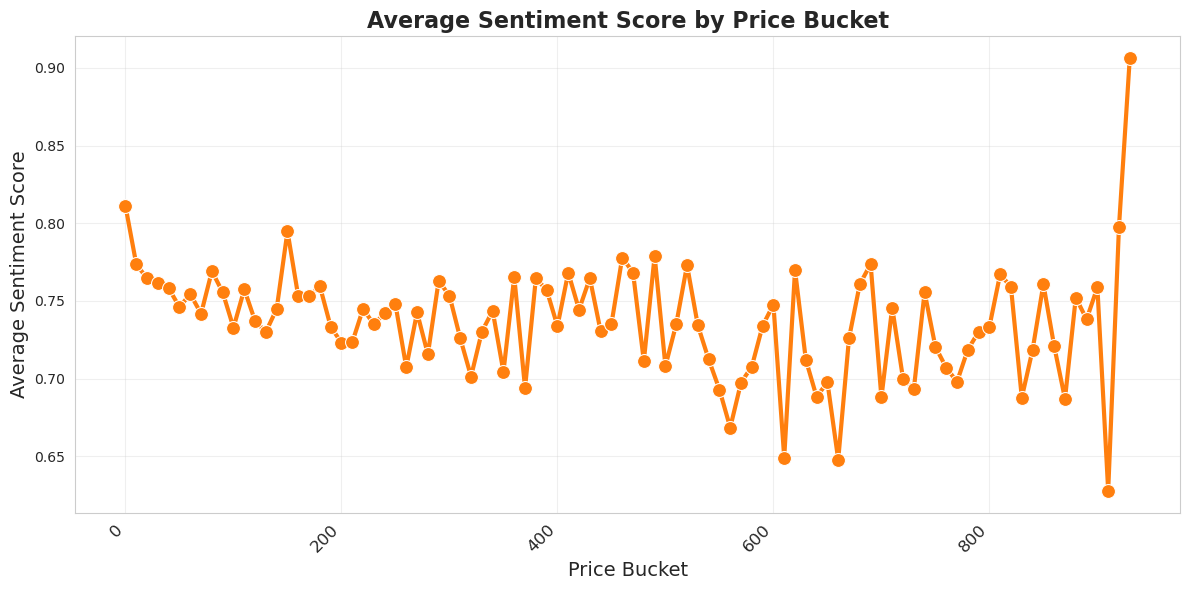

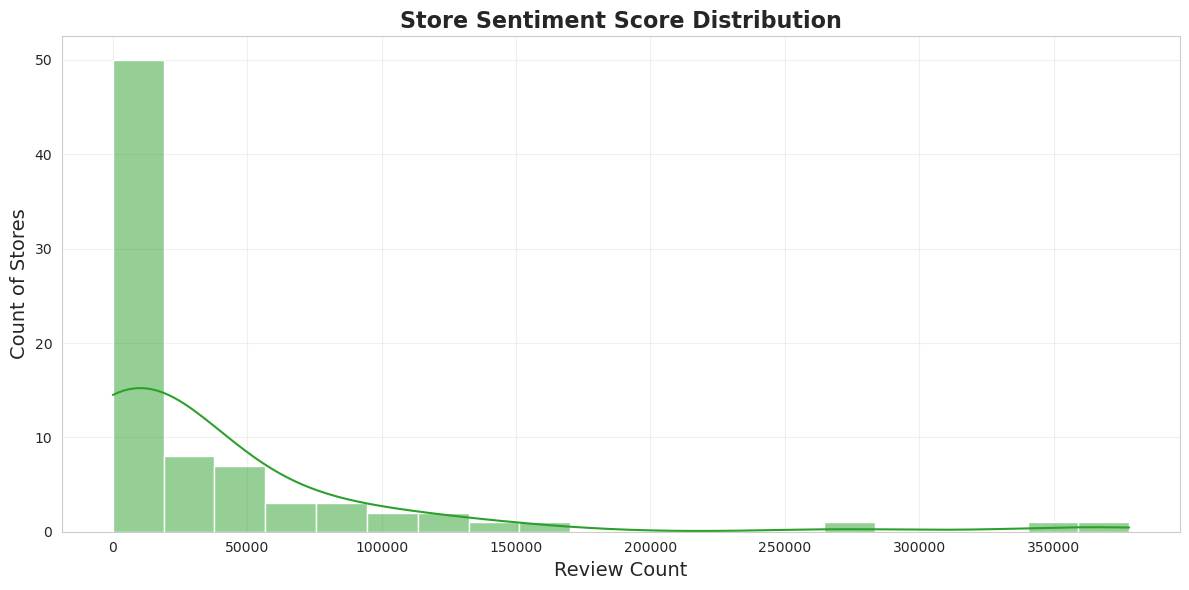


✅ All visual charts generated. Sentiment column auto-detected as: review_count


In [24]:
# ==========================
# M5 Visualization Final Fix
# ==========================
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Fix minus sign display issue
plt.rcParams['axes.unicode_minus'] = False

# --------------------------
# 1. Load Files (Verified)
# --------------------------
path = "/home/jovyan/work/data_lake/"

df_premium  = pd.read_csv(path + true_premium)
df_sentiment = pd.read_csv(path + store_stm)
df_price     = pd.read_csv(path + price_stm)

# Data validation + print column names
print("✅ Brand Premium Data:   ", df_premium.shape)
print("✅ Store Sentiment Data: ", df_sentiment.shape)
print("✅ Price Sentiment Data: ", df_price.shape)
print("\n=== Actual Column Names in Store Sentiment File ===")
print(df_sentiment.columns.tolist())

# --------------------------
# Chart 1: Brand Premium Bar Chart by Cluster (palette warning fixed)
# --------------------------
plt.figure(figsize=(16, 8))
# Fix warning: bind hue=x, hide legend — visually identical
"""
sns.barplot(data=df_premium, x="cluster", y="tier_avg_price", hue="cluster", palette="coolwarm", legend=False)
plt.title("Average Tier Price by Cluster (Brand Premium Analysis)", fontsize=20, weight='bold')
plt.xlabel("Cluster", fontsize=16)
plt.ylabel("Average Tier Price", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.tight_layout()
plt.savefig("pngs/M5/brand_premium_by_cluster.png", dpi=300, bbox_inches="tight")
plt.show(block=False)
#"""

# --------------------------
# Chart 2: Price Bucket vs Average Sentiment Line Chart (verified, no changes)
# --------------------------
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_price, x="price_bucket", y="avg_sentiment", marker="o", linewidth=3, color="#ff7f0e", markersize=10)
plt.title("Average Sentiment Score by Price Bucket", fontsize=16, weight='bold')
plt.xlabel("Price Bucket", fontsize=14)
plt.ylabel("Average Sentiment Score", fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pngs/M5/sentiment_by_price_bucket.png", dpi=300, bbox_inches="tight")
plt.show(block=False)

# --------------------------
# Chart 3: Store Sentiment Score Distribution Histogram (auto column detection)
# --------------------------
# Auto-match sentiment column: prefer sentiment_score, then sentiment, fallback to first numeric column
possible_cols = ["sentiment_score", "sentiment", "score", "sentiment_val"]
sentiment_col = None
for col in possible_cols:
    if col in df_sentiment.columns:
        sentiment_col = col
        break
# Fallback: use first numeric column if none matched
if not sentiment_col:
    numeric_cols = df_sentiment.select_dtypes(include=['number']).columns
    if len(numeric_cols) > 0:
        sentiment_col = numeric_cols[0]

# Plot histogram
plt.figure(figsize=(12, 6))
sns.histplot(data=df_sentiment, x=sentiment_col, bins=20, kde=True, color="#2ca02c", edgecolor='white')
plt.title("Store Sentiment Score Distribution", fontsize=16, weight='bold')
plt.xlabel(sentiment_col.replace("_", " ").title(), fontsize=14)
plt.ylabel("Count of Stores", fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pngs/M5/store_sentiment_distribution.png", dpi=300, bbox_inches="tight")
plt.show(block=True)

print(f"\n✅ All visual charts generated. Sentiment column auto-detected as: {sentiment_col}")

In [25]:
import time
print(f"Phase 3 & 4 Total Runtime: {time.time() - t_start_p3_p4:.2f} seconds")

Phase 3 & 4 Total Runtime: 937.53 seconds
